In [ ]:
'''多仓位比较'''

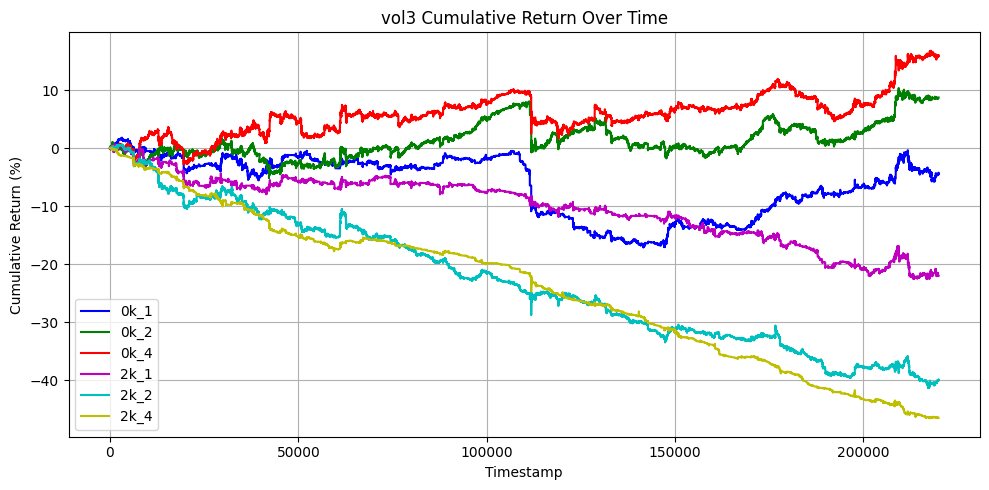

In [19]:
import os
import numpy as np
import matplotlib.pyplot as plt

# 不同实验路径
save_paths = [
    'MacroHFTcopy035/result/low_level/ETHUSDT/vol/k_1/1/label_3',
    'MacroHFTcopy035/result/low_level/ETHUSDT/vol/k_2/1/label_3',
    'MacroHFTcopy035/result/low_level/ETHUSDT/vol/k_4/1/label_3',
    'MacroHFT/result/low_level/ETHUSDT/vol/k_1/1/label_3',
    'MacroHFT/result/low_level/ETHUSDT/vol/k_2/1/label_3',
    'MacroHFT/result/low_level/ETHUSDT/vol/k_4/1/label_3'
    
]
labels = ['0k_1', '0k_2','0k_4','2k_1','2k_2','2k_4']
colors = ['b', 'g', 'r', 'm', 'c', 'y']

plt.figure(figsize=(10, 5))
for save_path, label, color in zip(save_paths, labels, colors):
    V_1 = np.load(os.path.join(save_path, 'require_money.npy'))
    reward = np.load(os.path.join(save_path, 'reward.npy'))

    # reward 可能是二维，取第一个episode
    if reward.ndim > 1:
        reward = reward[0]
    if V_1.ndim > 1:
        V_1 = V_1[0]

    total_reward = np.cumsum(reward)
    cum_return = np.divide(total_reward, V_1, out=np.zeros_like(total_reward, dtype=float), where=(V_1 != 0)) * 100
    timestamps = range(len(cum_return))

    plt.plot(timestamps, cum_return, label=label, color=color)

plt.xlabel('Timestamp')
plt.ylabel('Cumulative Return (%)')
plt.title('vol3 Cumulative Return Over Time')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('/home/ustc1958/lxy/vol3mutlik.png')

In [20]:
'''计算return'''

'计算return'

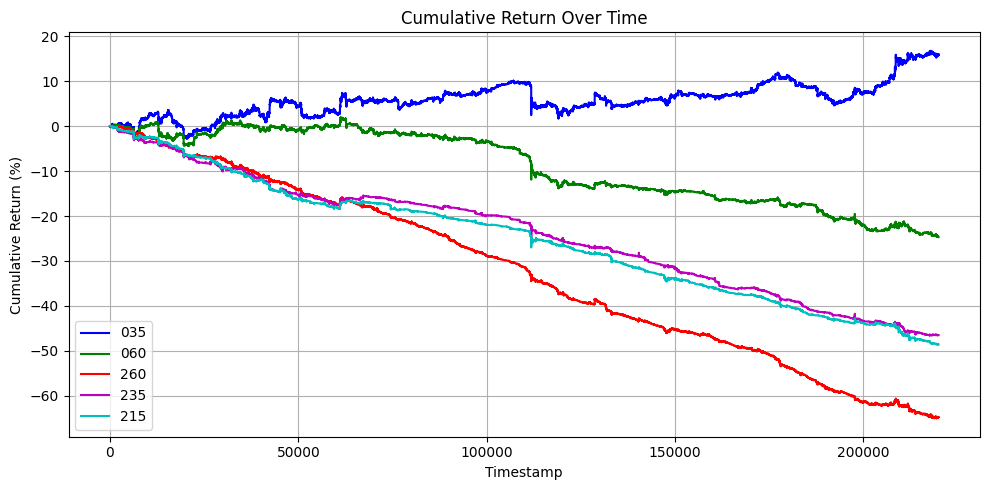

In [21]:
import os
import numpy as np
import matplotlib.pyplot as plt

# 不同实验路径
save_paths = [
    'MacroHFTcopy035/result/low_level/ETHUSDT/vol/k_4/1/label_3',
    'MacroHFT060/result/low_level/ETHUSDT/vol/k_4/1/label_3',
    'MacroHFTcopy260/result/low_level/ETHUSDT/vol/k_4/1/label_3',
    'MacroHFT/result/low_level/ETHUSDT/vol/k_4/1/label_3',
    '10.20.2148MacroHFT底层六个/result/low_level/ETHUSDT/vol/k_4/1/label_3'
]
labels = ['035', '060', '260', '235','215']
colors = ['b', 'g', 'r', 'm','c']

plt.figure(figsize=(10, 5))
for save_path, label, color in zip(save_paths, labels, colors):
    V_1 = np.load(os.path.join(save_path, 'require_money.npy'))
    reward = np.load(os.path.join(save_path, 'reward.npy'))

    # reward 可能是二维，取第一个episode
    if reward.ndim > 1:
        reward = reward[0]
    if V_1.ndim > 1:
        V_1 = V_1[0]

    total_reward = np.cumsum(reward)
    cum_return = np.divide(total_reward, V_1, out=np.zeros_like(total_reward, dtype=float), where=(V_1 != 0)) * 100
    timestamps = range(len(cum_return))

    plt.plot(timestamps, cum_return, label=label, color=color)

plt.xlabel('Timestamp')
plt.ylabel('Cumulative Return (%)')
plt.title('Cumulative Return Over Time')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('/home/ustc1958/lxy/cum_return.png')

In [22]:
'''判断收敛'''

'判断收敛'

Validation mean curves saved to: /home/ustc1958/lxy/result_all.png
Loss curves saved to: /home/ustc1958/lxy/loss_curve_all.png


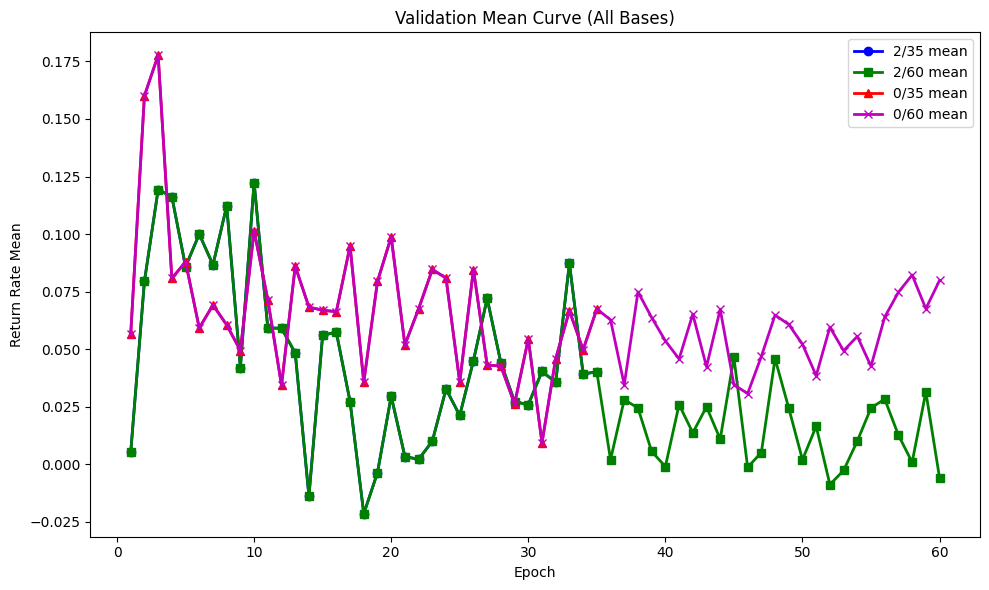

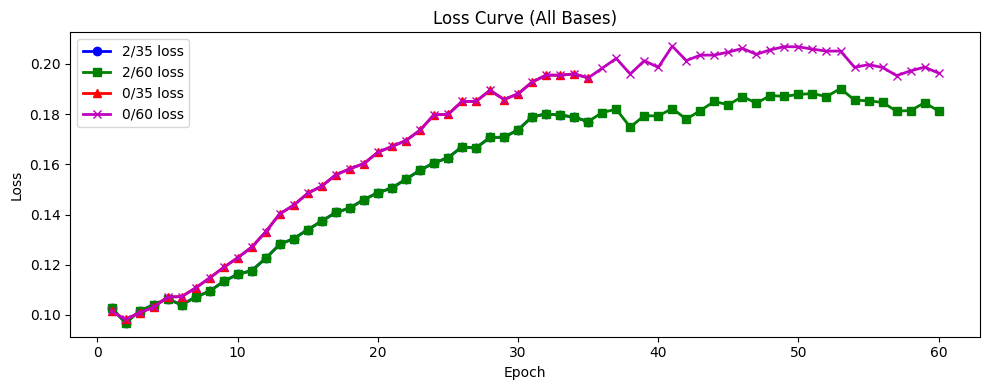

In [23]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

base_list = [
    Path(r'/home/ustc1958/lxy/MacroHFT/result/low_level/ETHUSDT/vol/k_4/1/label_3/seed_12345'),
    Path(r'/home/ustc1958/lxy/MacroHFTcopy260/result/low_level/ETHUSDT/vol/k_4/1/label_3/seed_12345'),
    Path(r'/home/ustc1958/lxy/MacroHFTcopy035/result/low_level/ETHUSDT/vol/k_4/1/label_3/seed_12345'),
    Path(r'/home/ustc1958/lxy/MacroHFT060/result/low_level/ETHUSDT/vol/k_4/1/label_3/seed_12345'),
]
save = Path(r'/home/ustc1958/lxy')
labels = ['2/35', '2/60','0/35', '0/60' ]
colors = ['b', 'g', 'r', 'm']
markers = ['o', 's', '^', 'x']  # 每条线一个marker

fig1, ax1 = plt.subplots(figsize=(10, 6))
fig2, ax2 = plt.subplots(figsize=(10, 4))

for base, label, color, marker in zip(base_list, labels, colors, markers):
    vals = []
    val_keys = [f'return_rate_mean_val_{i}.npy' for i in range(5)]
    for ep in sorted(base.glob('epoch_*'), key=lambda p: int(p.name.split('_')[1])):
        try:
            ep_num = int(ep.name.split('_')[1])
        except Exception:
            continue
        vdir = ep / 'val'
        val_files = [vdir / k for k in val_keys]
        if not all(f.exists() for f in val_files):
            continue
        try:
            vals_epoch = [float(np.load(f)) for f in val_files]
            mean = float(np.mean(vals_epoch))
            vals.append((ep_num, *vals_epoch, mean))
        except Exception:
            continue
    if not vals:
        continue
    vals_sorted = sorted(vals, key=lambda x: x[0])
    epochs = [e for e, *_ in vals_sorted]
    means = np.array([m for *_, m in vals_sorted], dtype=float)
    ax1.plot(epochs, means, label=f'{label} mean', color=color, marker=marker, linewidth=2)

    # loss
    losses = []
    for ep in sorted(base.glob('epoch_*'), key=lambda p: int(p.name.split('_')[1])):
        try:
            ep_num = int(ep.name.split('_')[1])
        except Exception:
            continue
        loss_f = ep / 'val' / 'loss.npy'
        if loss_f.exists():
            try:
                loss = float(np.load(loss_f))
                losses.append((ep_num, loss))
            except Exception:
                losses.append((ep_num, np.nan))
        else:
            losses.append((ep_num, np.nan))
    loss_epochs = [e for e, _ in losses]
    loss_vals = [l for _, l in losses]
    ax2.plot(loss_epochs, loss_vals, label=f'{label} loss', color=color, marker=marker, linewidth=2)

ax1.set_title('Validation Mean Curve (All Bases)')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Return Rate Mean')
ax1.legend()
fig1.tight_layout()
fig1.savefig(save / 'result_all.png')
print(f"Validation mean curves saved to: {save / 'result_all.png'}")

ax2.set_title('Loss Curve (All Bases)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
fig2.tight_layout()
fig2.savefig(save / 'loss_curve_all.png')
print(f"Loss curves saved to: {save / 'loss_curve_all.png'}")
